# Lab 1 - Feed-Forward Neural Networks

Our answers are in [NOTES.md](NOTES.md); our runs are in [LOGBOOK.md](LOGBOOK.md).

## Task 1 - Preprocessing

### Imports

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### 1.1 - Dataset and class balance

In [78]:
df = pd.read_csv("Materiale/dataset_lab_1.csv")

print(df['Label'])

df['Label'].value_counts()

0             Benign
1             Benign
2             Benign
3             Benign
4             Benign
            ...     
31502    Brute Force
31503    Brute Force
31504    Brute Force
31505    Brute Force
31506    Brute Force
Name: Label, Length: 31507, dtype: str


Label
Benign         20000
DoS Hulk        5000
PortScan        5000
Brute Force     1507
Name: count, dtype: int64

### 1.2 - Cleaning

We retain 29,384 of 31,507 samples after removing missing values, duplicates, infinities and selected negative values.

(29384, 17)
0
0
Label
Benign         19240
PortScan        4849
DoS Hulk        3868
Brute Force     1427
Name: count, dtype: int64
0


Text(0.5, 1.0, 'Distribution of Flow Duration')

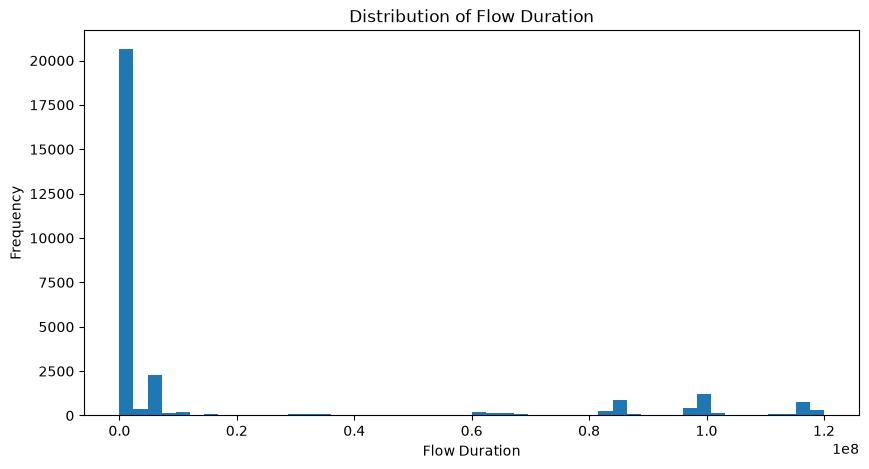

In [79]:
df = df.dropna()
df = df.drop_duplicates()
df["Label"].value_counts()
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()
cols_idx = [0, 1, 2, 3, 4, 7, 8, 9, 10, 11, 12, 14, 15]

cols = df.columns[cols_idx]

df = df[(df[cols] >= 0).all(axis=1)].copy()

print(df.shape)
print(df.isna().sum().sum())
print(df.duplicated().sum())
print(df["Label"].value_counts())
print(np.isinf(df.select_dtypes(include=np.number)).sum().sum())

plt.figure(figsize=(10, 5))

plt.hist(df["Flow Duration"], bins=50)

plt.xlabel("Flow Duration")
plt.ylabel("Frequency")
plt.title("Distribution of Flow Duration")

### 1.3 - Split and label encoding

We use a stratified 70/15/15 split with random_state=42 and fit the label encoder on training only.

In [80]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Label"])
Y = df["Label"]

print(df.shape)

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    Y,
    test_size=0.30,
    stratify=Y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)
print(X_train.shape)
print(X_test.shape)
print(X_val.shape)

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train)
y_val = label_encoder.transform(y_val)
y_test = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)
print(label_encoder.transform(label_encoder.classes_))

(29384, 17)


(20568, 16)
(4408, 16)
(4408, 16)
Classes: ['Benign' 'Brute Force' 'DoS Hulk' 'PortScan']
[0 1 2 3]


### 1.4 - Exploratory statistics

In [81]:
variances = X_train.var().sort_values(ascending=False)
print(variances)

print("\nFisher's Criterion")
scores = {}

for label in np.unique(y_train):

    X_class = X_train[y_train == label]
    X_rest  = X_train[y_train != label]

    mean_class = X_class.mean()
    mean_rest = X_rest.mean()

    var_class = X_class.var()
    var_rest = X_rest.var()

    fisher = (mean_class - mean_rest)**2 / (
        var_class + var_rest + 1e-9
    )

    scores[label] = fisher.mean()

scores = pd.Series(scores).sort_values()

print("0 = Benign, 1 = Brute Force, 2 = DoS Hulk, 3 = PortScan")
print(scores, "\n\nThe higher the score, the more discriminative the feature is for classification.")

Flow Duration             1.317755e+15
Flow Bytes/s              6.975741e+14
Fwd IAT Std               1.500167e+14
Flow IAT Mean             1.903953e+13
Flow Packets/s            3.648223e+10
Destination Port          3.104833e+08
Bwd Packet Length Max     4.038559e+06
Bwd Packet Length Mean    3.843754e+05
Fwd Packet Length Max     2.327037e+05
Packet Length Mean        8.741098e+04
Fwd Packet Length Mean    1.335118e+04
Subflow Fwd Packets       1.354483e+03
Total Fwd Packets         1.354483e+03
Down/Up Ratio             2.752730e-01
SYN Flag Count            3.890614e-02
Fwd PSH Flags             3.890614e-02
dtype: float64

Fisher's Criterion
0 = Benign, 1 = Brute Force, 2 = DoS Hulk, 3 = PortScan
0    0.092924
1    0.142394
3    0.170629
2    1.046245
dtype: float64 

The higher the score, the more discriminative the feature is for classification.


### 1.5 - Class proportions

In [82]:
print("\nTrain")

print(pd.Series(y_train).value_counts(normalize=True))

print("\nValidation")
print(pd.Series(y_val).value_counts(normalize=True))

print("\nTest")
print(pd.Series(y_test) .value_counts(normalize=True))


Train
0    0.654755
3    0.165014
2    0.131661
1    0.048571
Name: proportion, dtype: float64

Validation
0    0.654719
3    0.165154
2    0.131579
1    0.048548
Name: proportion, dtype: float64

Test
0    0.654946
3    0.164927
2    0.131579
1    0.048548
Name: proportion, dtype: float64


### 1.6 - StandardScaler

We fit on training only and reuse the scaler on validation/test.

In [83]:
from sklearn.preprocessing import StandardScaler

scaler_std = StandardScaler()

X_train_std = scaler_std.fit_transform(X_train)
X_val_std = scaler_std.transform(X_val)
X_test_std = scaler_std.transform(X_test)

### 1.7 - Alternative: log1p(Flow Duration) + StandardScaler

In [84]:
import numpy as np
from sklearn.preprocessing import StandardScaler

X_train_log = X_train.copy()
X_val_log = X_val.copy()
X_test_log = X_test.copy()

X_train_log["Flow Duration"] = np.log1p(X_train_log["Flow Duration"])
X_val_log["Flow Duration"] = np.log1p(X_val_log["Flow Duration"])
X_test_log["Flow Duration"] = np.log1p(X_test_log["Flow Duration"])

scaler_log = StandardScaler()

X_train_log_scaled = scaler_log.fit_transform(X_train_log)
X_val_log_scaled = scaler_log.transform(X_val_log)
X_test_log_scaled = scaler_log.transform(X_test_log)

### 1.8 - Scaling comparison

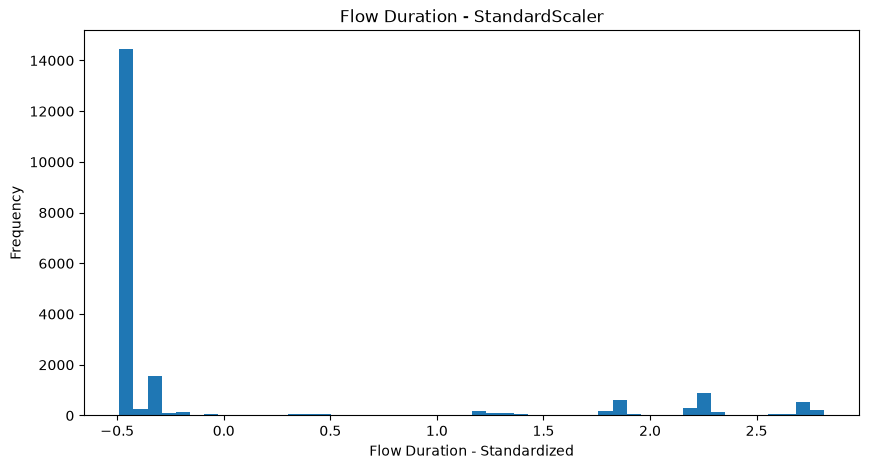

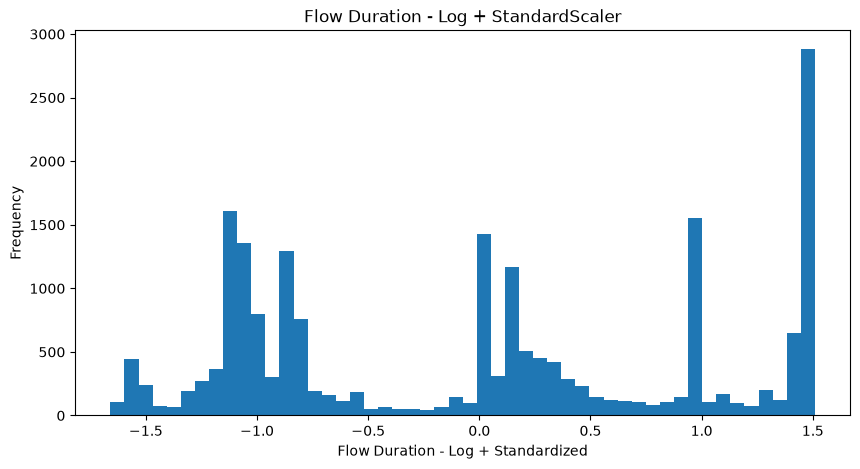

In [85]:
import matplotlib.pyplot as plt

flow_idx = X_train.columns.get_loc("Flow Duration")

plt.figure(figsize=(10, 5))
plt.hist(X_train_std[:, flow_idx], bins=50)
plt.xlabel("Flow Duration - Standardized")
plt.ylabel("Frequency")
plt.title("Flow Duration - StandardScaler")
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(X_train_log_scaled[:, flow_idx], bins=50)
plt.xlabel("Flow Duration - Log + Standardized")
plt.ylabel("Frequency")
plt.title("Flow Duration - Log + StandardScaler")
plt.show()

## Task 2A - Minimal classifier

Before training, we expect Brute Force to be hardest because it is rare, and DoS Hulk easier because its exploratory separability score is highest. We check this against the validation report.

We first used 100 epochs (historical run 1), then 150 epochs (run 2). The outputs below are run 2; both attempts are documented in NOTES.md and LOGBOOK.md.


In [86]:
import copy
import random
import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import classification_report, accuracy_score, f1_score

SEED = 42
HIDDEN_SIZE = 64
BATCH_SIZE = 64
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 0.01
MAX_EPOCHS = 150  # Increased from 100 to 150 epochs
PATIENCE = 20
MIN_DELTA = 0.5e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
device = torch.device("cpu")
print(f"Device: {device}; seed: {SEED}")

Device: cpu; seed: 42


### Model and data

In [87]:
class FFNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        return self.fc2(self.relu(self.fc1(x)))

train_dataset = TensorDataset(
    torch.tensor(X_train_std, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long),
)
validation_dataset = TensorDataset(
    torch.tensor(X_val_std, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long),
)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
)

model = FFNN(X_train_std.shape[1], HIDDEN_SIZE, len(label_encoder.classes_)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
)
print(model)
print(f"Train samples: {len(train_dataset)}; validation samples: {len(validation_dataset)}")

FFNN(
  (fc1): Linear(in_features=16, out_features=64, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=64, out_features=4, bias=True)
)
Train samples: 20568; validation samples: 4408


### Training and early stopping

We restore the checkpoint with the lowest validation loss; min_delta controls patience.

In [88]:
def fit(model, optimizer, train_loader, validation_loader,
        max_epochs=150, patience=20, min_delta=5e-5, verbose=True):
    criterion = nn.CrossEntropyLoss()
    device = next(model.parameters()).device
    train_losses, val_losses = [], []
    best_val_loss = float("inf")
    patience_reference = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0
    training_start = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        model.train()
        train_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(y_batch)
        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in validation_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                loss = criterion(model(X_batch), y_batch)
                val_loss += loss.item() * len(y_batch)
        val_loss /= len(validation_loader.dataset)
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if not np.isfinite(train_loss) or not np.isfinite(val_loss):
            print("Stopped: non-finite loss")
            break

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

        if val_loss < patience_reference - min_delta:
            patience_reference = val_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if verbose:
            print(f"Epoch {epoch:3d} | train CE {train_loss:.5f} | val CE {val_loss:.5f}")
        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    training_seconds = time.perf_counter() - training_start
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    if verbose:
        print(f"Restored epoch {best_epoch}: val CE={best_val_loss:.5f}")
        print(f"Training + epoch validation: {training_seconds:.2f} s")
    return dict(model=model, train=train_losses, val=val_losses,
                best_epoch=best_epoch, best_loss=best_val_loss,
                seconds=training_seconds)

In [89]:
baseline = fit(model, optimizer, train_loader, validation_loader,
               max_epochs=MAX_EPOCHS, patience=PATIENCE, min_delta=MIN_DELTA)
train_losses, val_losses = baseline["train"], baseline["val"]
best_epoch, best_val_loss = baseline["best_epoch"], baseline["best_loss"]
training_seconds = baseline["seconds"]

Epoch   1 | train CE 0.74733 | val CE 0.49031
Epoch   2 | train CE 0.40398 | val CE 0.34131
Epoch   3 | train CE 0.31045 | val CE 0.28211
Epoch   4 | train CE 0.26708 | val CE 0.26156
Epoch   5 | train CE 0.24384 | val CE 0.23353
Epoch   6 | train CE 0.22834 | val CE 0.22120
Epoch   7 | train CE 0.21710 | val CE 0.21154
Epoch   8 | train CE 0.20794 | val CE 0.20431
Epoch   9 | train CE 0.20040 | val CE 0.19660
Epoch  10 | train CE 0.19387 | val CE 0.19063
Epoch  11 | train CE 0.18793 | val CE 0.18552
Epoch  12 | train CE 0.18327 | val CE 0.18029
Epoch  13 | train CE 0.17885 | val CE 0.17647
Epoch  14 | train CE 0.17543 | val CE 0.17367
Epoch  15 | train CE 0.17235 | val CE 0.17071
Epoch  16 | train CE 0.16946 | val CE 0.16936
Epoch  17 | train CE 0.16713 | val CE 0.16746
Epoch  18 | train CE 0.16523 | val CE 0.16496
Epoch  19 | train CE 0.16338 | val CE 0.16400
Epoch  20 | train CE 0.16188 | val CE 0.16250
Epoch  21 | train CE 0.15990 | val CE 0.16216
Epoch  22 | train CE 0.15872 | val

### Loss curves

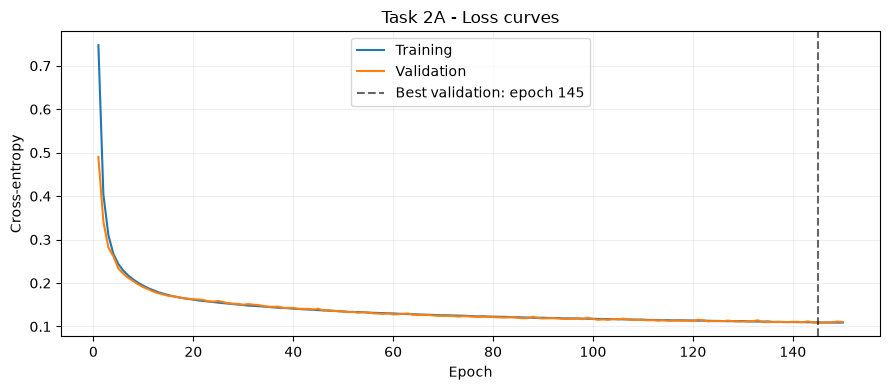

In [90]:
epochs = np.arange(1, len(train_losses) + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs, train_losses, label="Training")
ax.plot(epochs, val_losses, label="Validation")
ax.axvline(best_epoch, color="black", linestyle="--", alpha=0.6,
           label=f"Best validation: epoch {best_epoch}")
ax.set(xlabel="Epoch", ylabel="Cross-entropy", title="Task 2A - Loss curves")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

### Validation report

In [91]:
val_predictions = []
restored_val_loss = 0.0
with torch.no_grad():
    for X_batch, y_batch in validation_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model(X_batch)
        restored_val_loss += criterion(logits, y_batch).item() * len(y_batch)
        val_predictions.extend(logits.argmax(dim=1).cpu().tolist())
restored_val_loss /= len(validation_dataset)

class_names = label_encoder.classes_.tolist()
class_ids = list(range(len(class_names)))
val_report = classification_report(
    y_val, val_predictions, labels=class_ids, target_names=class_names,
    output_dict=True, zero_division=0,
)
val_accuracy = accuracy_score(y_val, val_predictions)
val_macro_f1 = f1_score(y_val, val_predictions, labels=class_ids, average="macro")
print(classification_report(
    y_val, val_predictions, labels=class_ids, target_names=class_names,
    digits=4, zero_division=0,
))
print(f"Validation accuracy: {val_accuracy:.4f}; macro-F1: {val_macro_f1:.4f}")
assert np.isclose(restored_val_loss, best_val_loss, rtol=1e-6, atol=1e-8)

              precision    recall  f1-score   support

      Benign     0.9663    0.9740    0.9701      2886
 Brute Force     0.8089    0.9299    0.8652       214
    DoS Hulk     0.9907    0.9207    0.9544       580
    PortScan     0.9496    0.9313    0.9404       728

    accuracy                         0.9578      4408
   macro avg     0.9289    0.9390    0.9325      4408
weighted avg     0.9591    0.9578    0.9581      4408

Validation accuracy: 0.9578; macro-F1: 0.9325


## Task 2B - Fundamentals

We change only scaling (S1) or LR (S2/S3), using fresh models and the same seed.

Before training, we expect unstable losses for S1, oscillation for S2 and slow learning for S3. Our predicted severity is S2 > S1 > S3.

In [92]:
def run_variant(train_x, val_x, lr):
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    def loader(x, y, shuffle):
        data = TensorDataset(torch.tensor(np.asarray(x), dtype=torch.float32),
                             torch.tensor(y, dtype=torch.long))
        return DataLoader(data, batch_size=64, shuffle=shuffle,
                          generator=torch.Generator().manual_seed(42))
    candidate = FFNN(16, 64, 4).to(device)
    opt = torch.optim.AdamW(candidate.parameters(), lr=lr, weight_decay=0.01)
    result = fit(candidate, opt, loader(train_x, y_train, True),
                 loader(val_x, y_val, False), verbose=False)
    if result["best_epoch"] == 0:
        return dict(result, accuracy=np.nan, macro_f1=np.nan)
    with torch.no_grad():
        predictions = candidate(torch.tensor(np.asarray(val_x), dtype=torch.float32,
                                             device=device)).argmax(1).cpu().numpy()
    result["accuracy"] = accuracy_score(y_val, predictions)
    result["macro_f1"] = f1_score(y_val, predictions, labels=range(4), average="macro", zero_division=0)
    return result

In [93]:
variants = {
    "S1 - raw inputs": (X_train, X_val, 5e-4),
    "S2 - high LR": (X_train_std, X_val_std, 0.5),
    "S3 - low LR": (X_train_std, X_val_std, 5e-6),
}
results_2b = {name: run_variant(*settings) for name, settings in variants.items()}

Early stopping at epoch 35
Early stopping at epoch 33


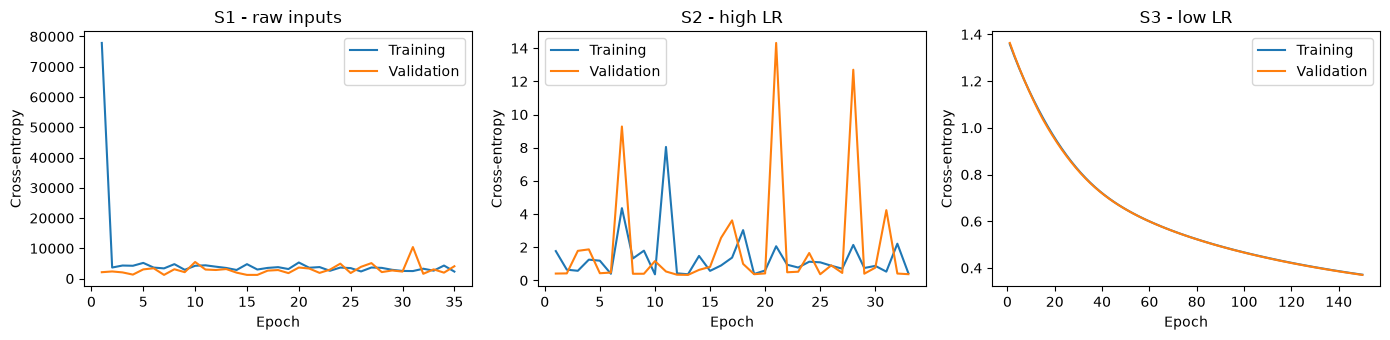

,Val loss,Accuracy,Macro-F1,Epochs,Best epoch,Train + val s
S1 - raw inputs,1218.416544,0.932623,0.893079,35.0,15.0,9.242539
S2 - high LR,0.333414,0.936252,0.895317,33.0,13.0,8.801009
S3 - low LR,0.370412,0.900408,0.739091,150.0,150.0,39.714106


In [94]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (name, result) in zip(axes, results_2b.items()):
    epochs = np.arange(1, len(result["train"]) + 1)
    ax.plot(epochs, result["train"], label="Training")
    ax.plot(epochs, result["val"], label="Validation")
    ax.set(title=name, xlabel="Epoch", ylabel="Cross-entropy")
    ax.legend()
fig.tight_layout()
plt.show()

pd.DataFrame({name: {"Val loss": r["best_loss"], "Accuracy": r["accuracy"],
                    "Macro-F1": r["macro_f1"], "Epochs": len(r["train"]),
                    "Best epoch": r["best_epoch"], "Train + val s": r["seconds"]}
              for name, r in results_2b.items()}).T

## Task 2C - Lock in our baseline

We tune the settings below on validation. Before the activation comparison, we expect ReLU to outperform Linear, especially on the harder classes. Both use the same initial weights and hyperparameters.

We select by validation macro-F1; each run restores its minimum-validation-loss checkpoint. Linear uses Identity between the two linear layers.

Our selected baseline is run 7: ReLU, lr=1e-3 and weight_decay=0.005 (best validation checkpoint: epoch 196).


In [114]:
HP_2C = dict(
    hidden_size=64,
    batch_size=64,
    lr=1e-3,  # Increased from 5e-4 to 1e-3
    weight_decay=0.005,  # Reduced from 0.01 to 0.005
    max_epochs=200,
    patience=20,
    min_delta=5e-5,
    seed=42,
)
print(pd.Series(HP_2C, name="Task 2C hyperparameters").to_string())

hidden_size      64.00000
batch_size       64.00000
lr                0.00100
weight_decay      0.00500
max_epochs      200.00000
patience         20.00000
min_delta         0.00005
seed             42.00000


In [115]:
def plot_confusion_2c(matrices, titles):
    names = label_encoder.classes_.tolist()
    fig, axes = plt.subplots(1, len(matrices), figsize=(6 * len(matrices), 5),
                             squeeze=False, layout="constrained")
    for ax, matrix, title in zip(axes.ravel(), matrices, titles):
        totals = matrix.sum(axis=1, keepdims=True)
        percentages = np.divide(100.0 * matrix, totals,
                                out=np.zeros_like(matrix, dtype=float), where=totals != 0)
        image = ax.imshow(percentages, cmap="Blues", vmin=0, vmax=100)
        ax.set(xticks=range(len(names)), yticks=range(len(names)),
               xticklabels=names, yticklabels=names,
               xlabel="Predicted class", ylabel="Actual class", title=title)
        plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
        ax.set_xticks(np.arange(len(names) + 1) - 0.5, minor=True)
        ax.set_yticks(np.arange(len(names) + 1) - 0.5, minor=True)
        ax.grid(which="minor", color="white", linewidth=2)
        ax.tick_params(which="minor", bottom=False, left=False)
        for i in range(len(names)):
            for j in range(len(names)):
                ax.text(j, i, f"{matrix[i, j]:,}\n{percentages[i, j]:.1f}%",
                        ha="center", va="center", fontsize=10,
                        color="white" if percentages[i, j] > 50 else "#16324f")
    fig.colorbar(image, ax=axes.ravel().tolist(), label="% of actual class", shrink=0.8)
    fig.suptitle("Confusion matrices - count and row percentage", fontsize=14)
    plt.show()

In [116]:
def train_2c(activation, **overrides):
    hp = {**HP_2C, **overrides}
    random.seed(hp["seed"])
    np.random.seed(hp["seed"])
    torch.manual_seed(hp["seed"])
    def loader(x, y, shuffle):
        data = TensorDataset(torch.tensor(np.asarray(x), dtype=torch.float32),
                             torch.tensor(y, dtype=torch.long))
        return DataLoader(data, batch_size=hp["batch_size"], shuffle=shuffle,
                          generator=torch.Generator().manual_seed(hp["seed"]))
    candidate = nn.Sequential(
        nn.Linear(X_train_std.shape[1], hp["hidden_size"]),
        nn.ReLU() if activation == "ReLU" else nn.Identity(),
        nn.Linear(hp["hidden_size"], len(label_encoder.classes_)),
    ).to(device)
    optimizer = torch.optim.AdamW(candidate.parameters(), lr=hp["lr"],
                                 weight_decay=hp["weight_decay"])
    result = fit(candidate, optimizer, loader(X_train_std, y_train, True),
                 loader(X_val_std, y_val, False), max_epochs=hp["max_epochs"],
                 patience=hp["patience"], min_delta=hp["min_delta"], verbose=False)
    if result["best_epoch"] == 0:
        raise RuntimeError(f"{activation}: no finite checkpoint; we cannot select this run")
    return result

def evaluate_2c(model, x, y, title):
    from sklearn.metrics import confusion_matrix
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(np.asarray(x), dtype=torch.float32,
                                    device=next(model.parameters()).device))
        loss = nn.functional.cross_entropy(
            logits, torch.tensor(y, dtype=torch.long, device=logits.device)).item()
        predictions = logits.argmax(1).cpu().numpy()
    names = label_encoder.classes_.tolist()
    labels = list(range(len(names)))
    report = classification_report(y, predictions, labels=labels, target_names=names,
                                   output_dict=True, zero_division=0)
    matrix = confusion_matrix(y, predictions, labels=labels)
    metrics = dict(loss=loss, accuracy=accuracy_score(y, predictions),
                   macro_precision=report["macro avg"]["precision"],
                   macro_recall=report["macro avg"]["recall"],
                   macro_f1=report["macro avg"]["f1-score"],
                   weighted_f1=report["weighted avg"]["f1-score"])
    print(f"\n{title}")
    print(classification_report(y, predictions, labels=labels, target_names=names,
                                digits=4, zero_division=0))
    print(pd.Series(metrics).round(5).to_string())
    return dict(metrics=metrics, report=report, predictions=predictions,
                confusion_matrix=matrix)

### ReLU versus Linear - validation

Early stopping at epoch 75

ReLU - validation
              precision    recall  f1-score   support

      Benign     0.9716    0.9844    0.9780      2886
 Brute Force     0.9132    0.9346    0.9238       214
    DoS Hulk     0.9665    0.9448    0.9555       580
    PortScan     0.9685    0.9286    0.9481       728

    accuracy                         0.9676      4408
   macro avg     0.9550    0.9481    0.9513      4408
weighted avg     0.9676    0.9676    0.9675      4408

loss               0.08986
accuracy           0.96756
macro_precision    0.95496
macro_recall       0.94810
macro_f1           0.95135
weighted_f1        0.96746

Linear - validation
              precision    recall  f1-score   support

      Benign     0.9472    0.9321    0.9396      2886
 Brute Force     0.8071    0.7430    0.7737       214
    DoS Hulk     0.9941    0.8672    0.9263       580
    PortScan     0.7827    0.9299    0.8500       728

    accuracy                         0.9140      4408
   macro a

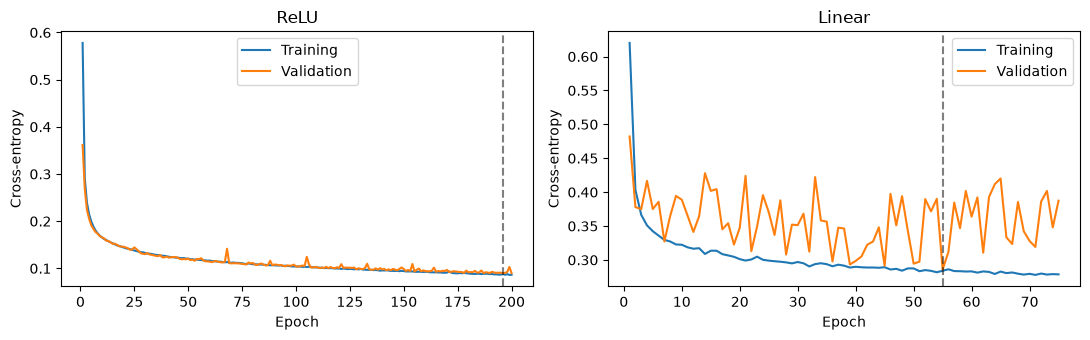


Per-class validation comparison
             ReLU precision  ReLU recall  ReLU f1-score  Linear precision  Linear recall  Linear f1-score
Benign               0.9716       0.9844         0.9780            0.9472         0.9321           0.9396
Brute Force          0.9132       0.9346         0.9238            0.8071         0.7430           0.7737
DoS Hulk             0.9665       0.9448         0.9555            0.9941         0.8672           0.9263
PortScan             0.9685       0.9286         0.9481            0.7827         0.9299           0.8500


In [117]:
results_2c = {name: train_2c(name) for name in ("ReLU", "Linear")}
validation_2c = {name: evaluate_2c(result["model"], X_val_std, y_val,
                                 f"{name} - validation")
                 for name, result in results_2c.items()}

summary_2c = pd.DataFrame({
    name: dict(validation_2c[name]["metrics"], epochs=len(result["train"]),
               best_epoch=result["best_epoch"], train_val_s=result["seconds"])
    for name, result in results_2c.items()
}).T
print("\nValidation comparison")
print(summary_2c.round(5).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, result) in zip(axes, results_2c.items()):
    epochs = np.arange(1, len(result["train"]) + 1)
    ax.plot(epochs, result["train"], label="Training")
    ax.plot(epochs, result["val"], label="Validation")
    ax.axvline(result["best_epoch"], color="black", linestyle="--", alpha=0.5)
    ax.set(title=name, xlabel="Epoch", ylabel="Cross-entropy")
    ax.legend()
fig.tight_layout()
plt.show()

per_class_2c = pd.DataFrame({
    f"{name} {metric}": {cls: result["report"][cls][metric]
                         for cls in label_encoder.classes_}
    for name, result in validation_2c.items()
    for metric in ("precision", "recall", "f1-score")
})
print("\nPer-class validation comparison")
print(per_class_2c.round(4).to_string())

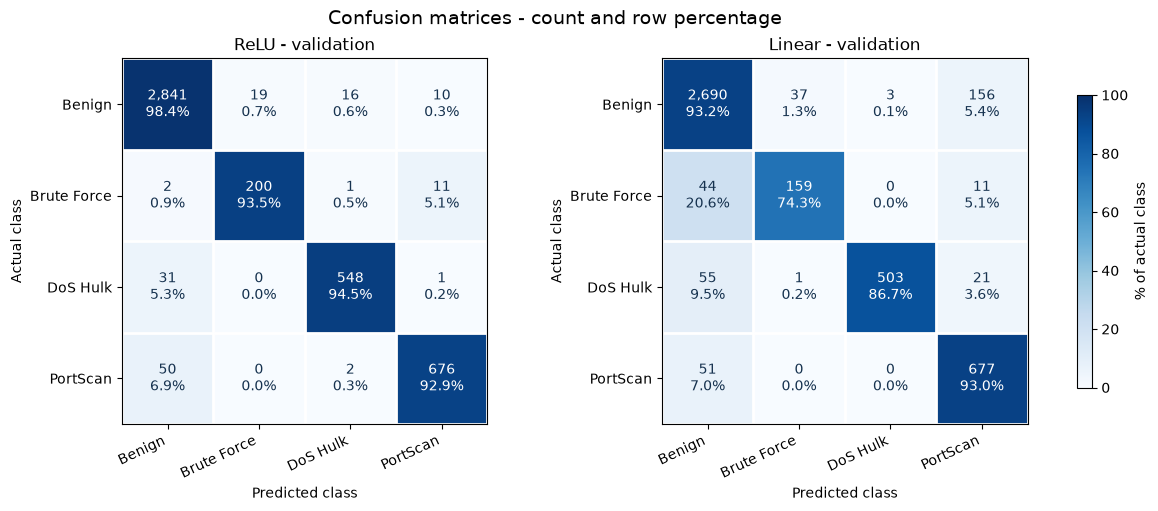

In [118]:
plot_confusion_2c(
    [result["confusion_matrix"] for result in validation_2c.values()],
    [f"{name} - validation" for name in validation_2c],
)

In [119]:
selected_activation_2c = max(
    validation_2c, key=lambda name: validation_2c[name]["metrics"]["macro_f1"])
baseline_2c = results_2c[selected_activation_2c]["model"]
locked_hp_2c = copy.deepcopy(HP_2C)
baseline_scaler_2c = copy.deepcopy(scaler_std)
baseline_classes_2c = label_encoder.classes_.copy()
baseline_features_2c = X_train.columns.tolist()
print(f"Our locked baseline: {selected_activation_2c}")
print(f"Validation macro-F1: {validation_2c[selected_activation_2c]['metrics']['macro_f1']:.4f}")

Our locked baseline: ReLU
Validation macro-F1: 0.9513


### Locked baseline - test

We evaluate test after fixing the hyperparameters and activation. We do not use test scores to select or retune the model.

In [120]:
test_2c = evaluate_2c(baseline_2c, X_test_std, y_test,
                      f"Locked {selected_activation_2c} baseline - test")
generalization_2c = pd.DataFrame({
    "Validation": validation_2c[selected_activation_2c]["metrics"],
    "Test": test_2c["metrics"],
}).T
print("\nOur locked baseline - generalization")
print(generalization_2c.round(5).to_string())
for metric in ("accuracy", "macro_f1"):
    gap = test_2c["metrics"][metric] - validation_2c[selected_activation_2c]["metrics"][metric]
    print(f"Test - validation {metric}: {gap:+.4f} ({100 * gap:+.2f} percentage points)")

print("\nPer-class F1: validation versus test")
print(pd.DataFrame({
    "Validation F1": {cls: validation_2c[selected_activation_2c]["report"][cls]["f1-score"]
                      for cls in baseline_classes_2c},
    "Test F1": {cls: test_2c["report"][cls]["f1-score"] for cls in baseline_classes_2c},
}).round(4).to_string())


Locked ReLU baseline - test
              precision    recall  f1-score   support

      Benign     0.9732    0.9813    0.9772      2887
 Brute Force     0.9156    0.9626    0.9385       214
    DoS Hulk     0.9701    0.9517    0.9608       580
    PortScan     0.9602    0.9285    0.9441       727

    accuracy                         0.9678      4408
   macro avg     0.9548    0.9560    0.9552      4408
weighted avg     0.9679    0.9678    0.9677      4408

loss               0.08612
accuracy           0.96779
macro_precision    0.95476
macro_recall       0.95603
macro_f1           0.95516
weighted_f1        0.96772

Our locked baseline - generalization
               loss  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1
Validation  0.08986   0.96756          0.95496       0.94810   0.95135      0.96746
Test        0.08612   0.96779          0.95476       0.95603   0.95516      0.96772
Test - validation accuracy: +0.0002 (+0.02 percentage points)
Test - validation macr

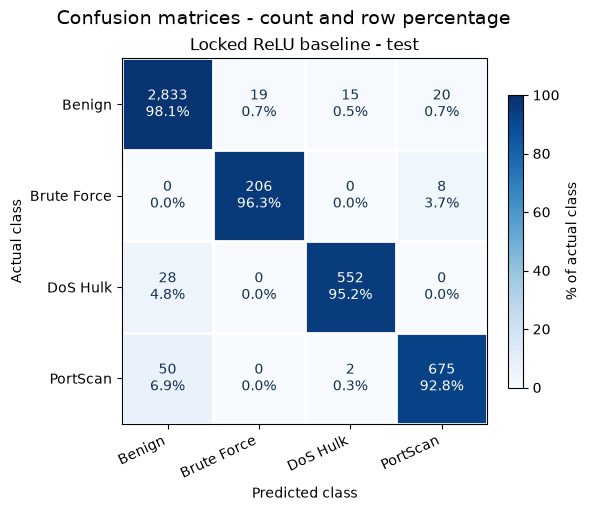

In [121]:
plot_confusion_2c([test_2c["confusion_matrix"]],
                  [f"Locked {selected_activation_2c} baseline - test"])

## Task 3 - Destination Port bias

## Task 4 - Class imbalance

## Task 5 - Hyperparameters

## Task 6 - Optimizations